<a href="https://colab.research.google.com/github/cathykam2006/Capstone-Project-Illuminado-Retinal--Image-Classification/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Exploratory data analysis

Questions this notebook answers before any modelling:
1. How imbalanced is the disease-risk label, and what accuracy does "always predict diseased" get? (Every model has to beat this.)
2. How common is each disease, and how often do diseases occur together?
3. Do images differ by camera / resolution in ways a model could exploit as a shortcut?

Run notebook 01 first.

In [1]:
# --- Setup (run once per session) -------------------------------------------
# On Colab: mounts Google Drive, clones this repo and installs requirements.
# Locally: just makes the `iluminado` package importable.
import os, sys, subprocess

REPO_URL = "https://github.com/cathykam2006/Capstone-Project-Illuminado-Retinal--Image-Classification.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/repo"], check=True)
    else:   # always use the latest code from GitHub
        subprocess.run(["git", "-C", "/content/repo", "pull", "-q"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

REPO_DIR = next(p for p in [os.getcwd(), os.path.dirname(os.getcwd())] if os.path.isdir(os.path.join(p, "iluminado")))
sys.path.insert(0, REPO_DIR)
print("Repo:", REPO_DIR)

Mounted at /content/drive
Repo: /content/repo


In [2]:
# --- Config: edit these paths ---------------------------------------------------
# PROJECT_DIR holds the cached images, trained models and results. On Colab it
# lives on your Google Drive so it survives between sessions.
PROJECT_DIR = "/content/drive/MyDrive/iluminado" if IN_COLAB else os.path.join(REPO_DIR, "work")
LABEL_DIR = os.path.join(REPO_DIR, "data")            # the three RFMiD label CSVs (in the repo)
MANIFEST = os.path.join(PROJECT_DIR, "manifest.csv")  # written by notebook 01
os.makedirs(PROJECT_DIR, exist_ok=True)

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from iluminado.data import TARGET_DISEASES

m = pd.read_csv(MANIFEST)
if IN_COLAB:   # copy the cached images from Drive to fast local disk once (Drive reads are slow)
    from iluminado.data import localize
    m = localize(m)
raw = pd.read_csv(os.path.join(PROJECT_DIR, "manifest_raw.csv"))
DISEASES = [c for c in m.columns if c not in ("split", "ID", "path", "Disease_Risk")]
print(len(m), "images,", len(DISEASES), "disease labels")

  copied 500/3200 images to local disk
  copied 1000/3200 images to local disk
  copied 1500/3200 images to local disk
  copied 2000/3200 images to local disk
  copied 2500/3200 images to local disk
  copied 3000/3200 images to local disk
  copied 3200/3200 images to local disk
3200 images, 45 disease labels


## 1. Disease risk balance and the naive baseline

In [4]:
risk = m.groupby("split")["Disease_Risk"].agg(n="size", diseased="sum", share_diseased="mean")
risk["accuracy of 'always diseased'"] = risk["share_diseased"]
risk.round(3)

,n,diseased,share_diseased,accuracy of 'always diseased'
split,,,,
test,640,506,0.791,0.791
train,1920,1519,0.791,0.791
val,640,506,0.791,0.791


About 79% of images in every split are diseased. A model that always says "diseased" is 79% accurate and completely useless. That is why the modelling notebooks report **AUC, sensitivity and specificity**, not accuracy.

The original README reported binary test accuracies of 0.73 to 0.78, which are all *below* this baseline.

## 2. Disease prevalence and co-occurrence

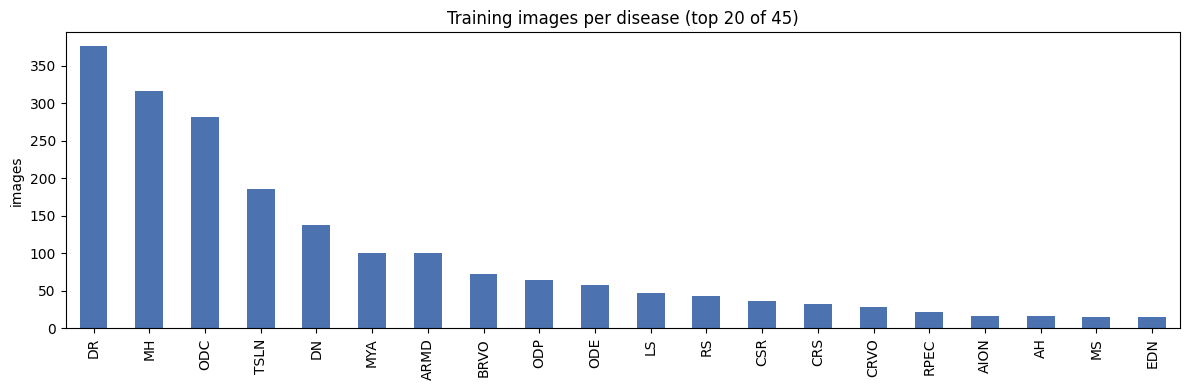

In [5]:
prev = m.loc[m.split == "train", DISEASES].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 4))
prev.head(20).plot.bar(ax=ax, color="#4C72B0")
ax.set_title("Training images per disease (top 20 of 45)"); ax.set_ylabel("images")
plt.tight_layout(); plt.show()

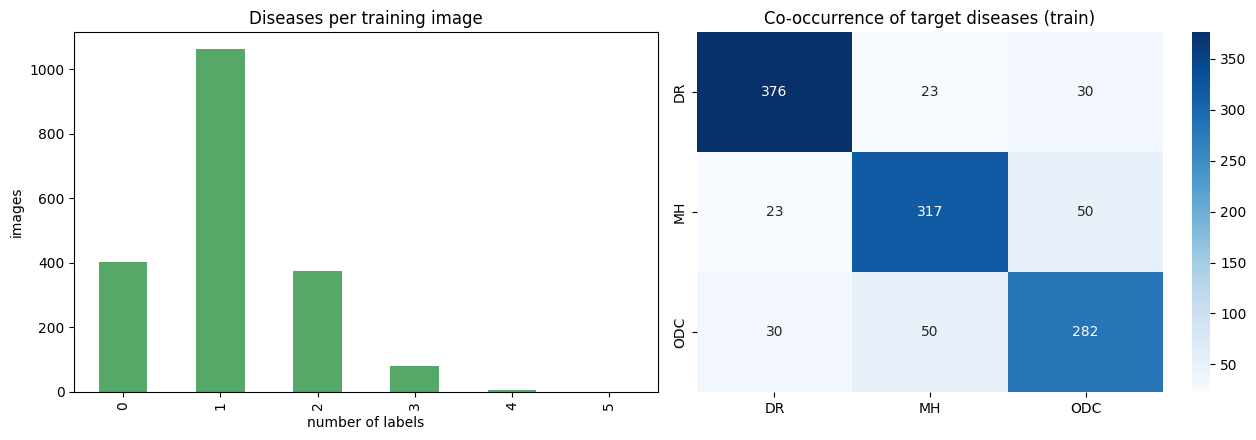

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
per_image = m.loc[m.split == "train", DISEASES].sum(axis=1)
per_image.value_counts().sort_index().plot.bar(ax=axes[0], color="#55A868")
axes[0].set_title("Diseases per training image"); axes[0].set_xlabel("number of labels"); axes[0].set_ylabel("images")

tr = m.loc[m.split == "train", TARGET_DISEASES]
co = tr.T.dot(tr)
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Co-occurrence of target diseases (train)")
plt.tight_layout(); plt.show()

Many images have several labels, and the three target diseases overlap. A softmax "pick one of three" model cannot represent an eye with both DR and ODC, so the disease model is **multi-label**: one independent yes/no output per disease.

## 3. Camera shortcut check

RFMiD comes from three cameras with different resolutions. If one camera captured a much higher share of healthy eyes, a model could score well by recognising the camera instead of anything about the retina. The original image size is the best available camera proxy (the Hugging Face copy only distinguishes the 3:2 cameras from the 4:3 one).

In [7]:
from iluminado.audit import camera_group, camera_vs_label
sizes = pd.read_csv(os.path.join(PROJECT_DIR, "image_sizes.csv"))
cam = m.merge(sizes, on=["split", "ID"])
cam["camera"] = [camera_group(w, h) for w, h in zip(cam.orig_w, cam.orig_h)]
display(pd.crosstab(cam.camera, cam.split, margins=True, margins_name="total"))
dev = cam[cam.split != "test"]                         # test labels stay untouched
summary, p, v = camera_vs_label(dev.camera, dev.Disease_Risk)
display(summary)
print(f"Camera vs disease label (train + val): chi-square p = {p:.3g}, Cramer's V = {v:.2f}  (0 = unrelated, 1 = camera decides the label)")

split,test,train,val,total
camera,,,,
2048x1536,73,150,53,276
2144x1424,439,1493,495,2427
4288x2848,128,277,92,497
total,640,1920,640,3200


,images,disease_rate
camera,,
2048x1536,203,0.315
2144x1424,1988,0.849
4288x2848,369,0.743


Camera vs disease label (train + val): chi-square p = 7.1e-71, Cramer's V = 0.36  (0 = unrelated, 1 = camera decides the label)


How to read Cramer's V: below about 0.1 the camera tells you almost nothing about the label. Above about 0.3, a model could lean on camera-specific appearance, so results should also be reported per camera. Either way, cropping every image to the fundus and resizing to one square size (notebook 01) removes the most obvious version of the shortcut, and Grad-CAM in the modelling notebooks checks what the model actually looks at.

## 4. Near-duplicate images across splits

The two eyes of one patient, or the same eye photographed twice, would inflate test scores if they sat on both sides of a split. RFMiD publishes no patient IDs, so every image is fingerprinted (a 256-bit difference hash) and pairs that are nearly identical are listed. An earlier run on the Hugging Face copy found **no** near-duplicates across splits; this re-checks it on the cached images.

In [8]:
from iluminado.audit import duplicate_report
dups = duplicate_report(m, max_hamming=6)
cross = dups[dups["crosses splits"]]
print(f"{len(dups)} near-duplicate pairs in total, {len(cross)} of them across splits")
dups.to_csv(os.path.join(PROJECT_DIR, "near_duplicates.csv"), index=False)
if len(cross):
    display(cross.sort_values("distance").head(20))
    print("Look at these pairs yourself; if they are true duplicates, drop the train/val copy from training.")

0 near-duplicate pairs in total, 0 of them across splits


## 5. Example images

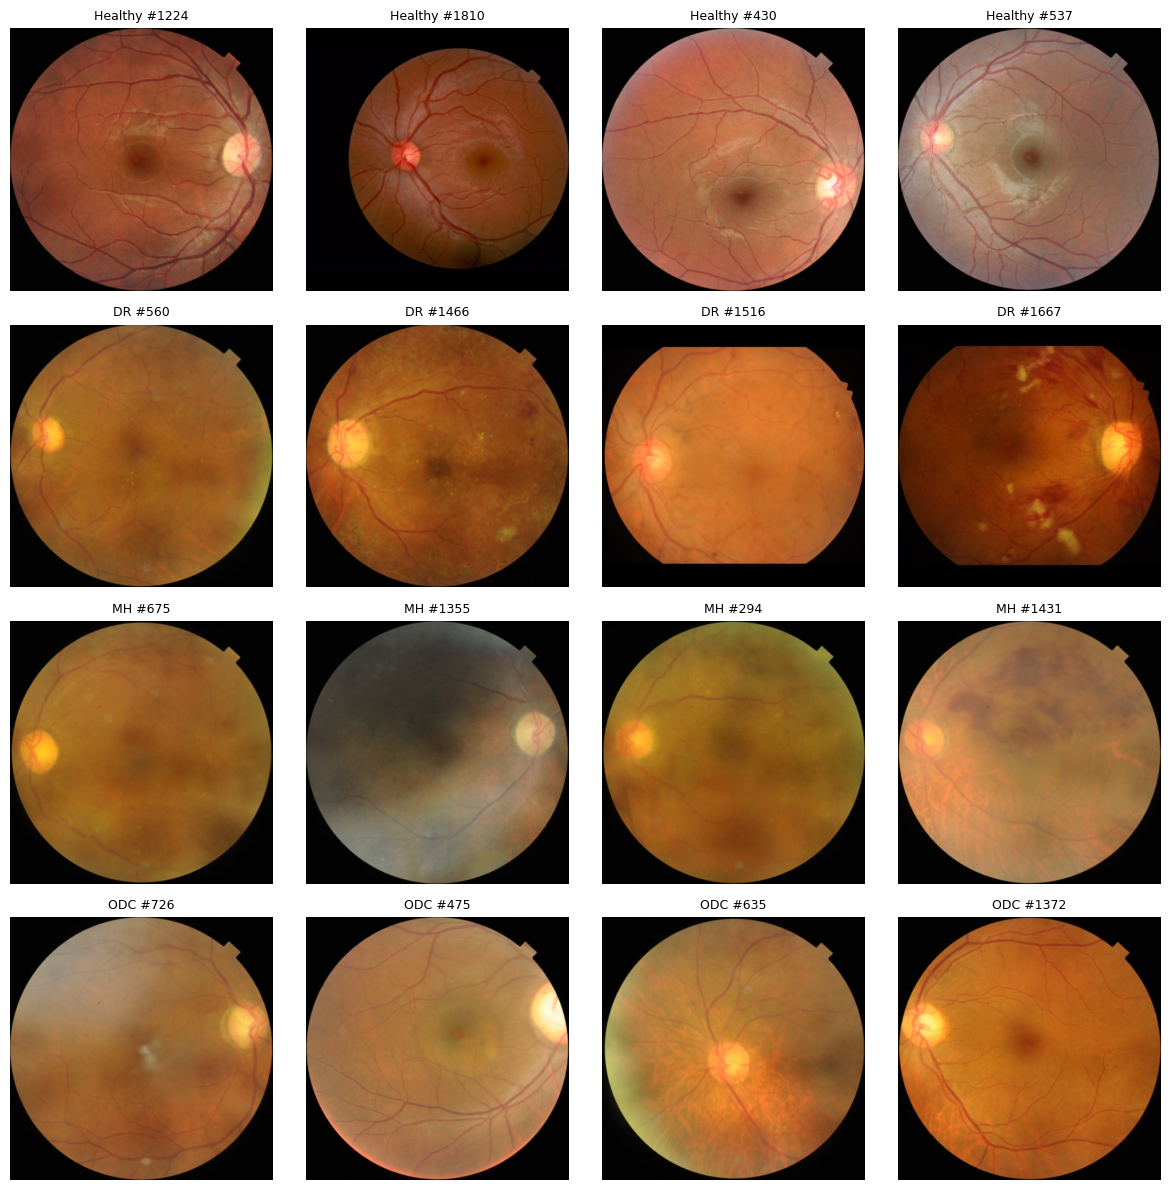

In [9]:
groups = {"Healthy": m[(m.split == "train") & (m.Disease_Risk == 0)]}
groups.update({d: m[(m.split == "train") & (m[d] == 1)] for d in TARGET_DISEASES})
fig, axes = plt.subplots(len(groups), 4, figsize=(12, 3 * len(groups)))
for r, (name, df) in enumerate(groups.items()):
    for c, (_, row) in enumerate(df.sample(4, random_state=0).iterrows()):
        axes[r, c].imshow(Image.open(row.path)); axes[r, c].axis("off")
        axes[r, c].set_title(f"{name} #{row.ID}", fontsize=9)
plt.tight_layout(); plt.show()